In [90]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import uncertainties as unc
import uncertainties.unumpy as unp
from scipy.optimize import curve_fit
from uncertainties import ufloat

In [91]:
# Import data
data1 = pd.read_csv('./Exercise1.csv')
data2 = pd.read_csv('./Exercise2.csv')

# Uncertainties
timebase_acc = 100e-6

data1_hor_div = 30e-6
data1_screen_width = 10 * data1_hor_div
data1_unc = timebase_acc * data1['Response time (μs)'] / 1e6 + .0016 * data1_screen_width
data1_unc *= 1e6 # Convert to μs

data2_hor_div = 100e-9
data2_screen_width = 10 * data2_hor_div
data2_time_unc = timebase_acc * data2['dX (ns)'] / 1e9 + .0016 * data2_screen_width + 200e-12
data2_time_unc *= 1e9 # Convert to ns

data2_vert_div = 1
data2_vert_full_scale = 8 * data2_vert_div
data2_vert_offset = -2
data2_vert_gain_acc = 3/100 * data2_vert_full_scale
data2_vert_offset_acc = data2_vert_div * .1 + 2e-3 + 1/100 * data2_vert_offset
data2_vert_unc = data2_vert_gain_acc + data2_vert_offset_acc + .25/100 * data2_vert_full_scale

Linear fit: y = (3.590±0.006)×10⁰ x + (-4.699±0.154)×10⁰
Chi2 = 34.15
Reduced chi2 = 0.88



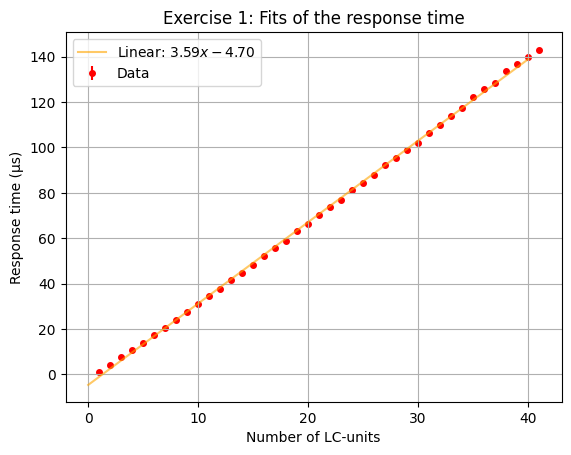

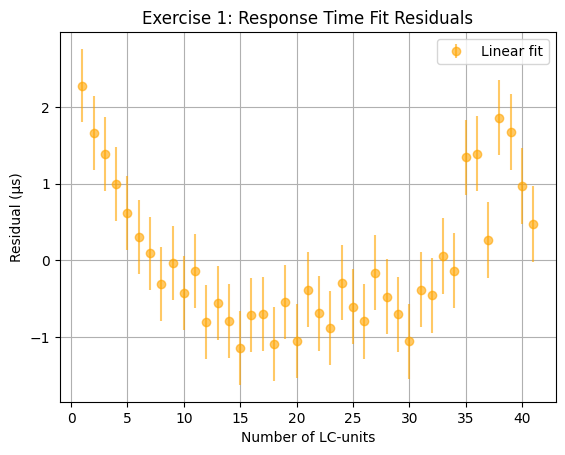

In [92]:
# Exercise 1: Determine the speed of pulse propagation along the line

# Given values
L0 = ufloat(1.5e-3, 1.5e-3 * 10/100) # Inductance of one LC-unit (H)
C0 = ufloat(0.01e-6, 0.01e-6 * 3/100) # Capacitance of one LC-unit (F)

# Theoretical speed of pulse propagation
v_theoretical = 1/unp.sqrt(L0*C0) # (2.582±0.135)×10⁵ LC-units/s

t = np.arange(0, 41, 1)

# Fit a linear model to the response time
lin = lambda x, a, b: np.polyval([a, b], x)
popt, pcov = curve_fit(lin, data1['Number of LC-units'], data1['Response time (μs)'], sigma=data1_unc, absolute_sigma=True)
perr = np.sqrt(np.diag(pcov))
upopt = unp.uarray(popt, perr)
v_fit = 1e6/upopt[0]
lin_formula = 'y = {:.3eP} x + {:.3eP}'.format(*upopt)
lin_res = data1['Response time (μs)'] - lin(data1['Number of LC-units'], *popt)

# Calculate chi2 and reduced chi2
chi2 = np.sum(lin_res**2)
dof = len(data1['Number of LC-units']) - len(popt)
chi2_red = chi2/dof

# Print results
print(f'Linear fit: {lin_formula}')
print(f'Chi2 = {chi2:.2f}')
print(f'Reduced chi2 = {chi2_red:.2f}\n')

# Plot fit
plt.plot(t, lin(t, *popt), label='Linear: ${:.2f}x{:+.2f}$'.format(*popt), color='orange', alpha=.6)

# Plot the data
plt.errorbar(data1['Number of LC-units'], data1['Response time (μs)'], yerr=data1_unc, fmt='o', label='Data', zorder=0, color='red', markersize=4)
plt.xlabel('Number of LC-units')
plt.ylabel('Response time (μs)')
plt.legend()
plt.grid()
plt.title('Exercise 1: Fits of the response time')
plt.savefig('exercise1-time_fits.png')
plt.show()

# Plot the residuals
plt.errorbar(data1['Number of LC-units'], lin_res, yerr=data1_unc, fmt='o', label='Linear fit', color='orange', alpha=.6)
plt.xlabel('Number of LC-units')
plt.ylabel('Residual (μs)')
plt.legend()
plt.grid()
plt.title('Exercise 1: Response Time Fit Residuals')
plt.savefig('exercise1-time_residuals.png')
plt.show()

In [93]:
print(f'Theoretical speed of pulse propagation: {v_theoretical:.3eP} LC-units/s')
print(f'Fitted speed of pulse propagation: {v_fit:.3eP} LC-units/s\n')

Theoretical speed of pulse propagation: (2.582±0.135)×10⁵ LC-units/s
Fitted speed of pulse propagation: (2.785±0.005)×10⁵ LC-units/s



Linear fit: y = (5.037±0.020)×10⁰ x + (1.283±0.974)×10⁰
Chi2 = 0.57
Reduced chi2 = 0.28



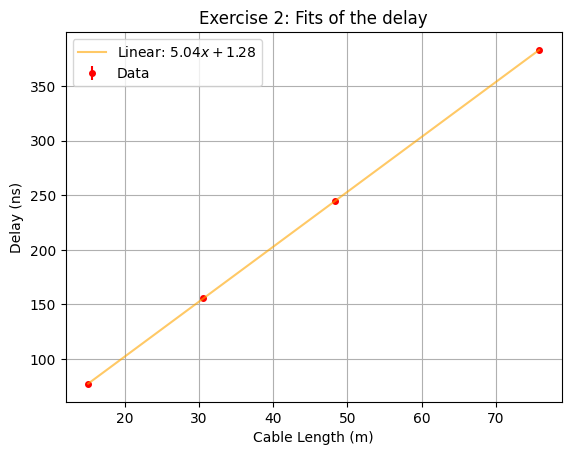

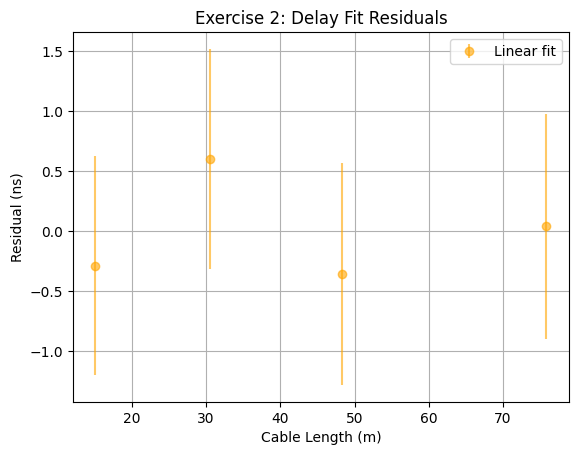

Theoretical speed of light in the cable: 1.999E+08 m/s
Fitted speed of light in the cable: (1.985±0.008)×10⁸ m/s



In [94]:
# Exercise 2: Comparing the pulse delay to the speed of light;
# Determining the attenuation factor & the characteristic impedance

# Given values
c = 299792458 # Speed of light in vacuum (m/s)
eps = 2.25 # Dielectric constant of the cable
mu = 1 # Permeability of the cable

# Theoretical speed of light in the cable
v_light = c/np.sqrt(eps*mu) # 2.0e8 m/s

open_circuit = data2[data2['Resistance (ohm)'] == np.inf]

line_lengths = open_circuit['Cable Length (m)']
line_lengths_unc = .02
line_delays = open_circuit['dX (ns)'] / 2
line_delays_unc = data2_time_unc[data2['Resistance (ohm)'] == np.inf] / 2

# Fit a linear model to the delay
popt, pcov = curve_fit(lin, line_lengths, line_delays, sigma=line_delays_unc, absolute_sigma=True)
perr = np.sqrt(np.diag(pcov))
upopt = unp.uarray(popt, perr)
v_cable = 1e9/upopt[0]
lin_formula = 'y = {:.3eP} x + {:.3eP}'.format(*upopt)
lin_res = line_delays - lin(line_lengths, *popt)

# Calculate chi2 and reduced chi2
chi2 = np.sum(lin_res**2)
dof = len(line_lengths) - len(popt)
chi2_red = chi2/dof

# Print results
print(f'Linear fit: {lin_formula}')
print(f'Chi2 = {chi2:.2f}')
print(f'Reduced chi2 = {chi2_red:.2f}\n')

# Plot fit
plt.plot(line_lengths, lin(line_lengths, *popt), label='Linear: ${:.2f}x{:+.2f}$'.format(*popt), color='orange', alpha=.6)

# Plot the data
plt.errorbar(line_lengths, line_delays, yerr=line_delays_unc, fmt='o', label='Data', zorder=0, color='red', markersize=4)
plt.xlabel('Cable Length (m)')
plt.ylabel('Delay (ns)')
plt.legend()
plt.grid()
plt.title('Exercise 2: Fits of the delay')
plt.savefig('exercise2-delay_fits.png')
plt.show()

# Plot the residuals
plt.errorbar(line_lengths, lin_res, yerr=line_delays_unc, fmt='o', label='Linear fit', color='orange', alpha=.6)
plt.xlabel('Cable Length (m)')
plt.ylabel('Residual (ns)')
plt.legend()
plt.grid()
plt.title('Exercise 2: Delay Fit Residuals')
plt.savefig('exercise2-delay_residuals.png')
plt.show()

# Print the results
print(f'Theoretical speed of light in the cable: {v_light:.3E} m/s')
print(f'Fitted speed of light in the cable: {v_cable:.3eP} m/s\n')

In [95]:
# Calculate the attenuation factor

data2_vert_unc_open_circuit = np.array([data2_vert_unc]*len(open_circuit['Amplitude (V)']))
line_voltage_initial = unp.uarray(open_circuit['Amplitude (V)'], data2_vert_unc_open_circuit)
line_voltage_drop = unp.uarray(open_circuit['dY (V)'], data2_vert_unc_open_circuit)
line_voltage_final = line_voltage_initial - line_voltage_drop
line_lengths = unp.uarray(line_lengths, np.array([line_lengths_unc]*len(line_lengths)))

attenuation_factor = 10 * unp.log10((line_voltage_final / line_voltage_initial)**2) / line_lengths
attenuation_factor = np.mean(attenuation_factor)
print(f'Attenuation factor: {attenuation_factor:.3eP} dB/m\n')

Attenuation factor: (4.177±1.274)×10⁻² dB/m



In [98]:
# Calculate the characteristic impedance

# rzL + rz0 = zl - z0
# (r+1) z0 = zl (1-r)
# z0 = (1+r)/(1-r) zl
data2.dropna(axis=0, inplace=True)
Z_L = data2['Resistance (ohm)']
1/np.inf

0.0